<a href="https://colab.research.google.com/github/gee666thu/Password-checker-/blob/main/exp6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
from tensorflow.keras.datasets import fashion_mnist
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress',10,
         'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training shape: (60000, 28, 28)
Testing shape: (10000, 28, 28)


In [5]:
_, X_train, _, y_train = train_test_split(X_train, y_train, test_size=10000,stratify=y_train, random_state=42)

_, X_test, _, y_test = train_test_split(X_test, y_test, test_size=2000,stratify=y_test, random_state=42)

In [6]:
X_train = X_train.reshape(-1, 784) / 255.0
X_test = X_test.reshape(-1, 784) / 255.0

print(X_train.shape)
print(X_test.shape)

(10000, 784)
(2000, 784)


In [8]:
ks = [1, 3, 5, 7, 9, 11, 15]
acc = []

print("K\tAccuracy\tTime")

for k in ks:
    m = KNeighborsClassifier(n_neighbors=k)
    m.fit(X_train, y_train)

    t = time.time()
    p = m.predict(X_test)

    a = accuracy_score(y_test, p)
    acc.append(a)

    print(k, "\t", round(a, 4), "\t\t",
          round(time.time()-t, 2))

K	Accuracy	Time
1 	 0.8025 		 3.2
3 	 0.811 		 2.5
5 	 0.8105 		 1.75
7 	 0.807 		 1.18
9 	 0.8095 		 1.18
11 	 0.8065 		 1.21
15 	 0.804 		 1.19


In [11]:
best = ks[acc.index(max(acc))]
print("Best K:", best)

m = KNeighborsClassifier(n_neighbors=best)
m.fit(X_train, y_train)
p = m.predict(X_test)

r = classification_report(y_test, p, output_dict=True)

print("\nClass Precision  Recall  F1-score")
for n in names:
    v = r[str(names.index(n))]
    print(f"{n:<12} {v['precision']:.2f}   {v['recall']:.2f}    {v['f1-score']:.2f}")

Best K: 3

Class Precision  Recall  F1-score
T-shirt/top  0.72   0.84    0.78
Trouser      0.98   0.97    0.98
Pullover     0.60   0.77    0.67
Dress        0.87   0.80    0.83
Coat         0.71   0.65    0.68
Sandal       0.99   0.81    0.89
Shirt        0.56   0.46    0.51
Sneaker      0.87   0.94    0.90
Bag          0.98   0.91    0.94
Ankle boot   0.88   0.97    0.92


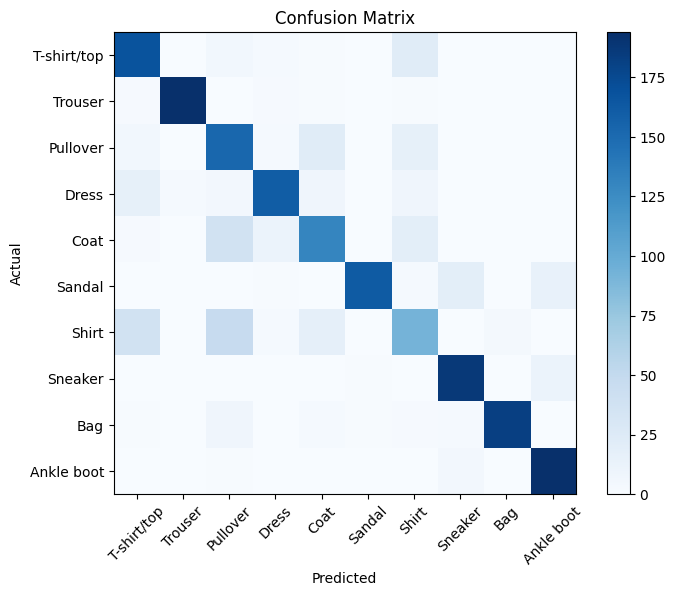

In [12]:
cm = confusion_matrix(y_test, p)

plt.figure(figsize=(8, 6))
plt.imshow(cm, cmap='Blues')
plt.colorbar()

plt.xticks(range(10), names, rotation=45)
plt.yticks(range(10), names)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()